# Verification Theater: A Confidence-Calibration Simulation

*Note: all data in this notebook are simulated. This is a design probe—not a human-subject study.*

This notebook compares stated confidence with outcome accuracy under two simulated conditions: an overconfident condition (A) and a condition whose correctness probability matches its stated confidence (B). It measures model-style confidence calibration only; it does not measure users’ trust, verification behavior, or decision quality.

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

In [2]:
np.random.seed(42)  # Make the simulation reproducible

n = 200  # Observations per condition

In [3]:
# Condition A: stated confidence exceeds the probability of a correct outcome
confidence_A = np.random.uniform(0.7, 0.99, n)
correct_A = (np.random.uniform(0, 1, n) < (confidence_A - 0.25)).astype(int)

In [4]:
# Condition B: probability of a correct outcome matches stated confidence
confidence_B = np.random.uniform(0.5, 0.95, n)
correct_B = (np.random.uniform(0, 1, n) < confidence_B).astype(int)

In [5]:
df = pd.DataFrame({
    "condition": ["A"] * n + ["B"] * n,
    "confidence": np.concatenate([confidence_A, confidence_B]),
    "correct":    np.concatenate([correct_A, correct_B]),
})

print(df.head(10))
print(df["correct"].groupby(df["condition"]).mean())

  condition  confidence  correct
0         A    0.808617        0
1         A    0.975707        1
2         A    0.912278        1
3         A    0.873611        0
4         A    0.745245        0
5         A    0.745238        1
6         A    0.716844        1
7         A    0.951191        1
8         A    0.874323        1
9         A    0.905341        1
condition
A    0.565
B    0.760
Name: correct, dtype: float64


## 1. Simulate two confidence conditions

Expected calibration error (ECE) summarizes the difference between stated confidence and observed accuracy across confidence bins. Lower ECE indicates closer agreement in this simulation; it does not, by itself, establish better user trust or decision outcomes.

In [6]:
def compute_ece(confidences, corrects, n_bins=5):
    """Compute expected calibration error using equal-width confidence bins."""
    bin_edges = np.linspace(0, 1, n_bins + 1)

    ece = 0.0
    total = len(confidences)

    for i in range(n_bins):
        low, high = bin_edges[i], bin_edges[i + 1]
        # Include confidence=1.0 in the final bin.
        if i == n_bins - 1:
            mask = (confidences >= low) & (confidences <= high)
        else:
            mask = (confidences >= low) & (confidences < high)
        count = mask.sum()

        if count == 0:
            continue

        avg_conf = confidences[mask].mean()
        avg_acc = corrects[mask].mean()
        ece += (count / total) * np.abs(avg_conf - avg_acc)

    return ece

In [7]:
A = df[df["condition"] == "A"]
B = df[df["condition"] == "B"]

ece_A = compute_ece(A["confidence"].values, A["correct"].values)
ece_B = compute_ece(B["confidence"].values, B["correct"].values)

print(f"Condition A (overconfident)  ECE = {ece_A:.3f}")
print(f"Condition B (confidence-matched)  ECE = {ece_B:.3f}")

Condition A (overconfident)  ECE = 0.275
Condition B (confidence-matched)  ECE = 0.026


## 2. Interpret the ECE results

Condition A is generated with a 0.25 confidence penalty, so it should be systematically overconfident. Condition B is generated so that each outcome’s probability of being correct matches its stated confidence. In this run, the estimated ECEs are 0.275 for A and 0.026 for B.

These values are estimates from one finite random sample, not fixed properties of the conditions. Sampling variability can move the estimates, especially with only 200 observations per condition. With five fixed-width bins, samples are also unevenly distributed across bins; report bin counts alongside calibration curves and consider repeating the simulation or using bootstrap intervals before making stronger comparisons.

In [8]:
def calibration_points(confidences, corrects, n_bins=5):
    bin_edges = np.linspace(0, 1, n_bins + 1)
    xs, ys = [], []

    for i in range(n_bins):
        low, high = bin_edges[i], bin_edges[i + 1]
        mask = (confidences >= low) & (confidences < high)
        if mask.sum() == 0:
            continue

        xs.append(confidences[mask].mean())
        ys.append(corrects[mask].mean())
    
    return xs, ys

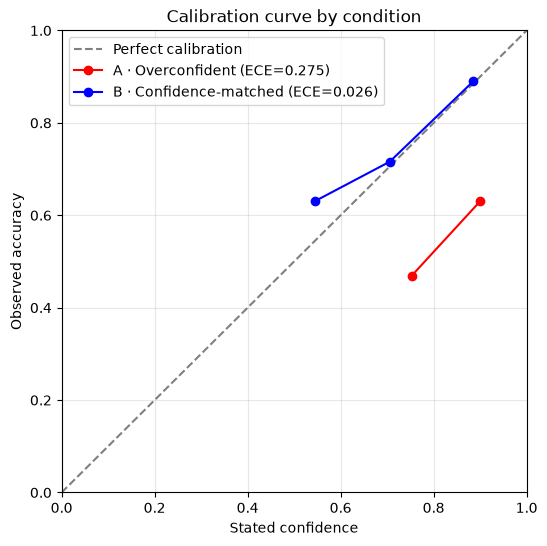

In [9]:
xA, yA = calibration_points(A["confidence"].values, A["correct"].values)
xB, yB = calibration_points(B["confidence"].values, B["correct"].values)

plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
plt.plot(xA, yA, "o-", color="red", label=f"A · Overconfident (ECE={ece_A:.3f})")
plt.plot(xB, yB, "o-", color="blue", label=f"B · Confidence-matched (ECE={ece_B:.3f})")

plt.xlabel("Stated confidence")
plt.ylabel("Observed accuracy")
plt.title("Calibration curve by condition")
plt.legend()
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.show()

## 3. Open questions for Dr. Alex

With condition A built to be overconfident and B built to be
well-calibrated, the ECE gap came out large and clean (0.275 vs 0.026),
and the calibration curve shows A sitting well below the diagonal while B
tracks it closely. Two questions I'd genuinely like your input on:

1. Here the A-vs-B gap exists because I designed it into the simulated
   data. In a real AI system, would this kind of calibration gap show up
   on its own, or does a model have to be specifically trained to "know
   what it doesn't know"?

2. ECE measures the *model's* calibration. But what I ultimately care
   about is the *user's* trust and decision quality. Does a lower ECE
   actually lead users to trust the system more appropriately — and how
   would you connect the model-side metric to the user-side outcome?